# Day 24 / 100 — LabelAlignment QA | Final Research Notebook

**Purpose:** reproducible, auditable YOLOv8n baseline for three source-defined classes (`class_imperfect label`, `class_no label`, `class_perfect label`). All four Kaggle sources are inventoried, but only Bottle Label Detection v2 is used for the main model. Dataset provenance is recorded; secondary ontologies are **not** merged.

**Scientific boundary:** axis-aligned detection cannot measure printed label rotation or calibrated offset. `class_no label` means a source-defined image annotation, not certified factory compliance. No pass/fail claim without a geometric measurement protocol, tolerances and independent verification.

**Observed prior execution (not a promised rerun):** 210 primary images, research split 136 train / 39 val / 35 test; 45 epochs (best at 30); 35-image held-out mAP@50 ≈ 0.987 and mAP@50–95 ≈ 0.740. New runs must take metrics from actual output. The small test set warrants caution.

**Run:** attach the four datasets at the paths below in Kaggle, enable GPU, then Run All. Default `MODE='auto'` trains **only if** no previously trained checkpoint is accessible; mounting the exported checkpoint plus `MODE='reuse'` avoids retraining. If reusing a checkpoint, verify it was fitted on the same split and dataset version (do not silently evaluate on training images). Output is saved to `/kaggle/working/labelalignment_day24` and an artifact ZIP. This notebook does **not** include historical model weights.


## 00 · Configuration and environment

In [1]:
from __future__ import annotations
import os, sys, re, json, shutil, hashlib, random, time, subprocess, importlib.util, warnings, zipfile
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from IPython.display import display

SEED=42
random.seed(SEED); np.random.seed(SEED)
SOURCES={
 'big_cola':Path('/kaggle/input/datasets/youssefeldemerdashh/big-cola-bottles-dataset-for-yolo-quality-control'),
 'label_v2':Path('/kaggle/input/datasets/loliwibu/bottle-label-detection-v2'),
 'label_other':Path('/kaggle/input/datasets/yashvisave/dataset-for-bottle-label-detection'),
 'water_defects':Path('/kaggle/input/datasets/jihadakbr/water-bottle-defect-level-detection-dataset')}
OUT=Path('/kaggle/working/labelalignment_day24')
REPORT=OUT/'reports'; PLOTS=OUT/'plots'; MODELS=OUT/'models'; RUNS=OUT/'runs'; CONFIG=OUT/'configs'; EXAMPLES=OUT/'examples'
for d in (OUT,REPORT,PLOTS,MODELS,RUNS,CONFIG,EXAMPLES):d.mkdir(parents=True,exist_ok=True)
MODE='auto' # auto | train | reuse | audit
EXISTING_CHECKPOINT=None # e.g. '/kaggle/input/my-day24-weights/labelalignment_primary_best.pt'
CFG={'primary_source':'label_v2','epochs':65,'patience':15,'imgsz':640,'batch':16,'workers':2,
     'pretrained':'yolov8n.pt','train_to_test_fraction':0.20,'minimum_test_images':10,
     'onnx_export':True,'max_examples':12}
SOURCE_URLS={
 'big_cola':'https://www.kaggle.com/datasets/youssefeldemerdashh/big-cola-bottles-dataset-for-yolo-quality-control',
 'label_v2':'https://www.kaggle.com/datasets/loliwibu/bottle-label-detection-v2',
 'label_other':'https://www.kaggle.com/datasets/yashvisave/dataset-for-bottle-label-detection',
 'water_defects':'https://www.kaggle.com/datasets/jihadakbr/water-bottle-defect-level-detection-dataset'
}
print('Python:',sys.version.split()[0], 'Mode:',MODE)
for k,v in SOURCES.items():print(k,'FOUND' if v.is_dir() else 'MISSING',v)
if not SOURCES[CFG['primary_source']].is_dir():raise FileNotFoundError('Attach the primary dataset in Kaggle Add Input first.')
(REPORT/'environment.json').write_text(json.dumps({'python':sys.version,'seed':SEED,'sources':{k:str(v) for k,v in SOURCES.items()},'cfg':CFG,'mode':MODE},indent=2))

Python: 3.13.15 Mode: auto
big_cola FOUND /kaggle/input/datasets/youssefeldemerdashh/big-cola-bottles-dataset-for-yolo-quality-control
label_v2 FOUND /kaggle/input/datasets/loliwibu/bottle-label-detection-v2
label_other FOUND /kaggle/input/datasets/yashvisave/dataset-for-bottle-label-detection
water_defects FOUND /kaggle/input/datasets/jihadakbr/water-bottle-defect-level-detection-dataset


787

## 01 · Inspect all four source datasets and ontologies

In [2]:
IMAGE_EXT={'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
try:import yaml
except ImportError:
 subprocess.check_call([sys.executable,'-m','pip','install','-q','pyyaml']);import yaml

def names_from_yaml(cfg):
 raw=cfg.get('names',{})
 if isinstance(raw,dict):return [str(raw[k]) for k in sorted(raw,key=lambda x:int(x))]
 if isinstance(raw,list):return [str(x) for x in raw]
 return []
def count_images(root):return sum(p.is_file() and p.suffix.lower() in IMAGE_EXT for p in root.rglob('*'))
inventory=[];yamls=[]
for name,root in SOURCES.items():
 if not root.is_dir():inventory.append({'source':name,'found':False});continue
 configs=sorted(p for p in root.rglob('*') if p.is_file() and p.name.lower() in {'data.yaml','dataset.yaml'})
 inventory.append({'source':name,'found':True,'root':str(root),'images':count_images(root),'yaml_files':[str(p.relative_to(root)) for p in configs],'top_level':[p.name for p in list(root.iterdir())[:25]]})
 for cfg_path in configs:
  try:
   raw=yaml.safe_load(cfg_path.read_text(encoding='utf-8-sig'))
   if not isinstance(raw,dict):raise ValueError('YAML must be a mapping')
   yamls.append({'source':name,'config_path':str(cfg_path),'names':names_from_yaml(raw),'train':str(raw.get('train')),'val':str(raw.get('val',raw.get('valid'))),'test':str(raw.get('test'))})
  except Exception as exc:yamls.append({'source':name,'config_path':str(cfg_path),'error':repr(exc)})
display(pd.DataFrame(inventory));display(pd.DataFrame(yamls))
(REPORT/'source_inventory.json').write_text(json.dumps({'inventory':inventory,'yamls':yamls},indent=2,ensure_ascii=False))

,source,found,root,images,yaml_files,top_level
0,big_cola,True,/kaggle/input/datasets/youssefeldemerdashh/big...,377,[],"[obj.data, obj.names, obj_train_data, train.txt]"
1,label_v2,True,/kaggle/input/datasets/loliwibu/bottle-label-d...,210,[data.yaml],"[README.dataset.txt, README.roboflow.txt, data..."
2,label_other,True,/kaggle/input/datasets/yashvisave/dataset-for-...,396,[],[dataset]
3,water_defects,True,/kaggle/input/datasets/jihadakbr/water-bottle-...,1500,[data.yaml],"[data.yaml, images, labels]"


,source,config_path,names,train,val,test
0,label_v2,/kaggle/input/datasets/loliwibu/bottle-label-d...,"[class_imperfect label, class_no label, class_...",../train/images,../valid/images,../test/images
1,water_defects,/kaggle/input/datasets/jihadakbr/water-bottle-...,"[bottle_ron88, bottle_other_brand, defect_low_...",images/train,images/val,None


2084

## 02 · Resolve actual primary YOLO splits

In [3]:
def resolve_split(yaml_path,cfg,split):
 base=yaml_path.parent
 tokens={'train':['train'],'val':['valid','val'],'test':['test']}[split]
 declared=cfg.get('val',cfg.get('valid')) if split=='val' else cfg.get(split)
 candidates=[]
 if declared:
  original=Path(str(declared).replace('\\','/'))
  if not original.is_absolute():candidates.append(base/original)
  if len(original.parts)>=2:candidates.append(base/original.parts[-2]/original.parts[-1])
 for token in tokens:candidates.extend([base/token/'images',base/'dataset'/token/'images'])
 for d in candidates:
  if d.is_dir() and any(f.is_file() and f.suffix.lower() in IMAGE_EXT for f in d.iterdir()):return d.resolve()
 return None
entries=[y for y in yamls if y.get('source')==CFG['primary_source'] and 'error' not in y]
if len(entries)!=1:raise RuntimeError(f'Expected exactly one primary YAML; got {len(entries)}')
PRIMARY_YAML=Path(entries[0]['config_path']); RAW_CFG=yaml.safe_load(PRIMARY_YAML.read_text(encoding='utf-8-sig'))
CLASS_NAMES=names_from_yaml(RAW_CFG)
if not CLASS_NAMES:raise RuntimeError('Missing class names in primary YAML')
SPLITS={s:resolve_split(PRIMARY_YAML,RAW_CFG,s) for s in ('train','val','test')}
if SPLITS['train'] is None or SPLITS['val'] is None:raise RuntimeError('Primary train/val images not found')
print('Primary classes:',CLASS_NAMES,'Splits:',SPLITS)

Primary classes: ['class_imperfect label', 'class_no label', 'class_perfect label'] Splits: {'train': PosixPath('/kaggle/input/datasets/loliwibu/bottle-label-detection-v2/train/images'), 'val': PosixPath('/kaggle/input/datasets/loliwibu/bottle-label-detection-v2/valid/images'), 'test': None}


## 03 · Image/annotation validity and source manifest

In [4]:
def sha256_file(path):
 h=hashlib.sha256()
 with Path(path).open('rb') as f:
  for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
 return h.hexdigest()
def audit_split(split,folder):
 imgs=sorted(f for f in folder.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_EXT)
 label_dir=folder.parent/'labels';labels={f.stem:f for f in label_dir.glob('*.txt')} if label_dir.is_dir() else {}
 rows=[];errors=[];counts=Counter()
 stems={f.stem for f in imgs}
 for lbl in labels.values():
  if lbl.stem not in stems:errors.append({'split':split,'issue':'orphan_label','path':str(lbl)})
 for img in imgs:
  lbl=labels.get(img.stem)
  if lbl is None:errors.append({'split':split,'issue':'missing_label','path':str(img)});continue
  try:
   with Image.open(img) as im:im.verify()
   found=[]
   for lineno,line in enumerate(lbl.read_text(encoding='utf-8-sig').splitlines(),1):
    if not line.strip():continue
    parts=line.split()
    if len(parts)!=5:raise ValueError(f'line {lineno} requires class + xywh')
    cls=int(parts[0]);xywh=[float(v) for v in parts[1:]]
    if cls not in range(len(CLASS_NAMES)):raise ValueError(f'line {lineno}: class id {cls} invalid')
    if not all(np.isfinite(v) and 0<=v<=1 for v in xywh):raise ValueError('coords invalid')
    x,y,w,h=xywh
    if min(w,h)<=0 or x-w/2 < -1e-3 or y-h/2 < -1e-3 or x+w/2 > 1.001 or y+h/2 > 1.001:raise ValueError('box exceeds image')
    found.append(cls);counts[CLASS_NAMES[cls]]+=1
   rows.append({'split':split,'image':str(img),'label':str(lbl),'stem':img.stem,'sha256':sha256_file(img),'n_boxes':len(found),'classes':','.join(map(str,sorted(set(found))))})
  except (ValueError,OSError,UnidentifiedImageError) as exc:errors.append({'split':split,'issue':'invalid_image_or_label','path':str(img),'detail':repr(exc)})
 return rows,errors,counts
all_rows=[];all_errors=[];all_counts=Counter()
for split,folder in SPLITS.items():
 if folder is None:continue
 r,e,c=audit_split(split,folder);all_rows.extend(r);all_errors.extend(e);all_counts.update(c)
 print(split,len(r),'valid;',len(e),'errors')
df=pd.DataFrame(all_rows)
if df.empty:raise RuntimeError('No valid primary images')
df.to_csv(REPORT/'primary_manifest_source.csv',index=False)
audit={'image_counts':df.groupby('split').size().to_dict(),'box_counts':dict(all_counts),'error_count':len(all_errors),'errors':all_errors,'classes':CLASS_NAMES}
(REPORT/'primary_audit.json').write_text(json.dumps(audit,indent=2))
print(json.dumps({k:v for k,v in audit.items() if k!='errors'},indent=2))
if all_errors:raise RuntimeError('Invalid images/labels: audit failed; see reports/primary_audit.json')

train 171 valid; 0 errors
val 39 valid; 0 errors
{
  "image_counts": {
    "train": 171,
    "val": 39
  },
  "box_counts": {
    "class_imperfect label": 62,
    "class_perfect label": 122,
    "class_no label": 26
  },
  "error_count": 0,
  "classes": [
    "class_imperfect label",
    "class_no label",
    "class_perfect label"
  ]
}


## 04 · Duplicate check and held-out partition (validation is preserved)

In [5]:
def family_of(stem):
 s=re.sub(r'\.rf\.[0-9a-f]+$','',stem,flags=re.I)
 s=re.sub(r'([_-](flip|rot|aug|copy)[_-]?\d*)$','',s,flags=re.I)
 return s.lower()
df['family']=df['stem'].map(family_of)
collisions={}
for field in ('sha256','family'):
 conflicting=df.groupby(field)['split'].agg(lambda v:sorted(set(v)))
 collisions[field]={str(k):v for k,v in conflicting[conflicting.map(len)>1].items()}
(REPORT/'cross_split_collisions.json').write_text(json.dumps(collisions,indent=2))
print('Original split collisions:',{k:len(v) for k,v in collisions.items()})
if any(collisions.values()):raise RuntimeError('Original source train/val/test overlaps by hash/family. Stop.')
train_df=df[df.split=='train'].copy();val_df=df[df.split=='val'].copy();provided_test=df[df.split=='test'].copy()
if not provided_test.empty:
 final_train=train_df.copy();test_df=provided_test.copy();test_policy='provided_source_test'
else:
 from sklearn.model_selection import GroupShuffleSplit
 if train_df.family.nunique()<5:raise RuntimeError('Too few independent families')
 ix_tr,ix_te=next(GroupShuffleSplit(n_splits=1,test_size=CFG['train_to_test_fraction'],random_state=SEED).split(train_df,groups=train_df.family))
 final_train=train_df.iloc[ix_tr].copy();test_df=train_df.iloc[ix_te].copy();test_policy='group_holdout_from_original_train'
if len(test_df)<CFG['minimum_test_images']:raise RuntimeError('Insufficient heldout test images')
for field in ('sha256','family'):
 sets=[set(d[field]) for d in (final_train,val_df,test_df)]
 if any(sets[i]&sets[j] for i,j in ((0,1),(0,2),(1,2))):raise RuntimeError(f'Cross split {field} leakage')
combined=pd.concat([final_train.assign(research_split='train'),val_df.assign(research_split='val'),test_df.assign(research_split='test')],ignore_index=True)
combined.to_csv(REPORT/'research_split_manifest.csv',index=False)
(REPORT/'split_policy.json').write_text(json.dumps({'policy':test_policy,'train':len(final_train),'val':len(val_df),'test':len(test_df),'seed':SEED,'limit':'Hash and filename family checks do not rule out visual near duplicates.'},indent=2))
print('Final research split:',{s:len(d) for s,d in [('train',final_train),('val',val_df),('test',test_df)]})

Original split collisions: {'sha256': 0, 'family': 0}
Final research split: {'train': 136, 'val': 39, 'test': 35}


## 04b · Near-duplicate visual review (perceptual hashes)

Exact SHA-256 and filename checks are useful but insufficient for near-duplicates. This diagnostic computes an 8×8 difference hash (dHash) on each primary image and reports **suspected** cross-split visually similar pairs. dHash is heuristic: collisions do not prove leakage and non-collisions do not prove independence. For suspicious pairs, inspect `near_duplicate_review.png` and the CSV *before* treating test metrics as independent. We do **not** alter the split post hoc based on test metrics. New split decisions must happen before training and require retraining the model.


Near-duplicate CANDIDATES across splits: 26


,split_a,split_b,image_a,image_b,hamming_distance,manual_review
0,train,val,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,1,pending
1,train,test,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,3,pending
2,val,test,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,3,pending
3,val,test,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,3,pending
4,train,test,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,4,pending
5,train,val,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,4,pending
6,train,test,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,4,pending
7,train,test,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,4,pending
8,val,test,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,4,pending
9,train,val,/kaggle/input/datasets/loliwibu/bottle-label-d...,/kaggle/input/datasets/loliwibu/bottle-label-d...,5,pending


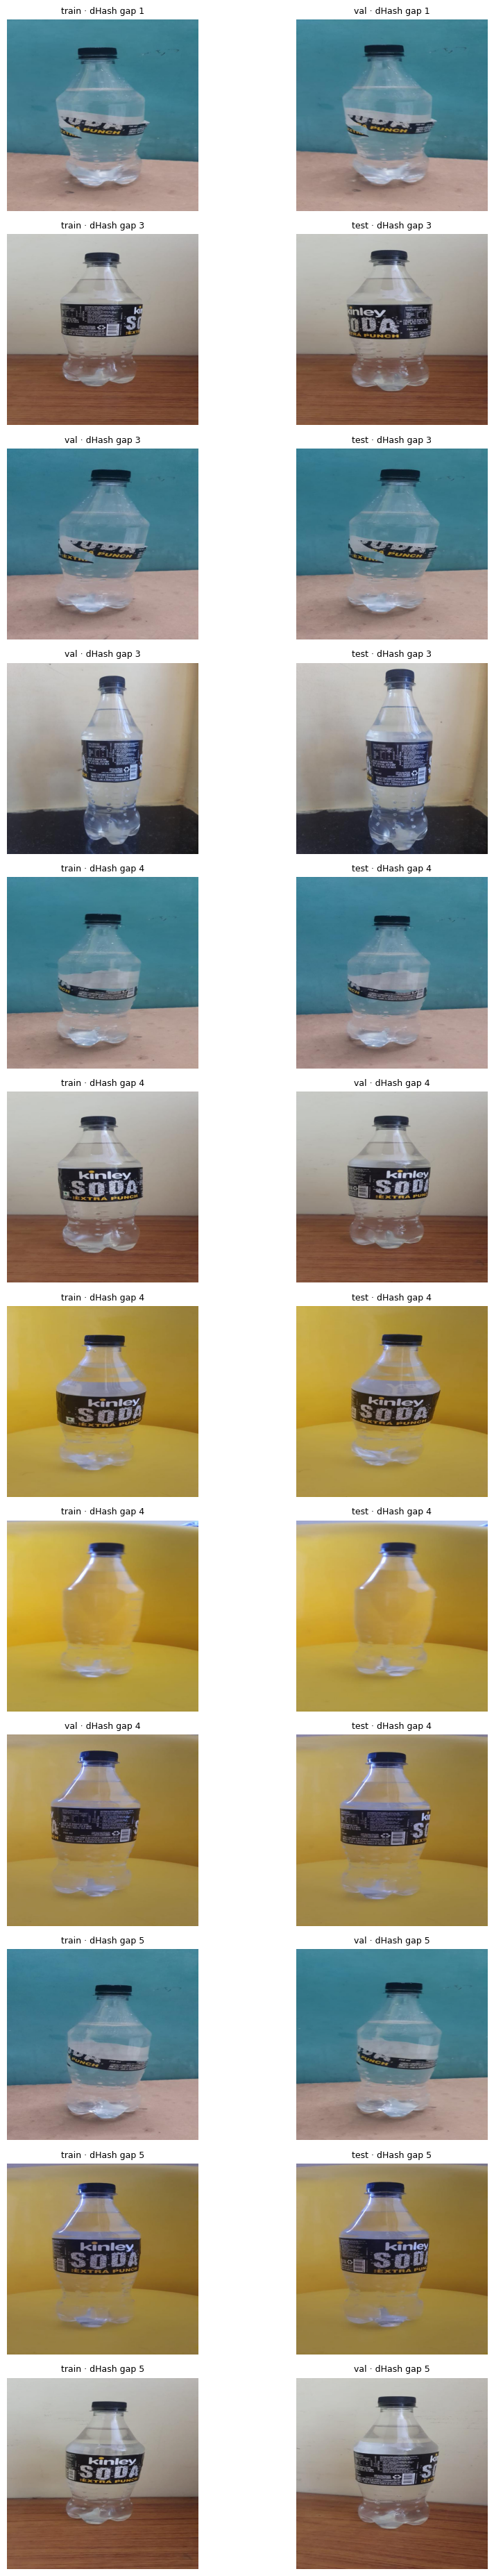

REVIEW REQUIRED: check visually; do not assert complete leakage freedom.


185

In [6]:
from itertools import combinations

def visual_dhash(path):
    with Image.open(path) as im:
        rgb = ImageOps.exif_transpose(im).convert('L').resize((9,8), Image.Resampling.LANCZOS)
        a = np.asarray(rgb)
    bits = (a[:,1:] > a[:,:-1]).ravel()
    return sum((int(v) << i) for i,v in enumerate(bits))

visual_manifest = combined[['image','research_split','sha256','family']].copy()
visual_manifest['dhash'] = [visual_dhash(p) for p in visual_manifest.image]
visual_manifest['dhash_hex'] = visual_manifest.dhash.map(lambda v:format(v,'016x'))
visual_manifest.drop(columns=['dhash']).to_csv(REPORT/'visual_hash_manifest.csv',index=False)

# Across split only, hamming distance <= 5 is a review flag, not automatic exclusion.
flags=[]
rows=visual_manifest.to_dict('records')
for a,b in combinations(rows,2):
    if a['research_split']==b['research_split']:continue
    hd=(a['dhash']^b['dhash']).bit_count()
    if hd<=5:
        flags.append({'split_a':a['research_split'],'split_b':b['research_split'],
                      'image_a':a['image'],'image_b':b['image'],'hamming_distance':hd,
                      'manual_review':'pending'})
flags=sorted(flags,key=lambda r:r['hamming_distance'])
flag_df=pd.DataFrame(flags,columns=['split_a','split_b','image_a','image_b','hamming_distance','manual_review'])
flag_df.to_csv(REPORT/'near_duplicate_candidates.csv',index=False)
print('Near-duplicate CANDIDATES across splits:',len(flags))
if flags:
    display(flag_df.head(20))
    sample_pairs=flags[:min(12,len(flags))]
    fig,axes=plt.subplots(len(sample_pairs),2,figsize=(10,3.1*len(sample_pairs)),squeeze=False)
    for row_ix,pair in enumerate(sample_pairs):
        for col,key in enumerate(('image_a','image_b')):
            with Image.open(pair[key]) as im:
                axes[row_ix,col].imshow(ImageOps.exif_transpose(im).convert('RGB'))
            axes[row_ix,col].set_title(f"{pair['split_a'] if col==0 else pair['split_b']} · dHash gap {pair['hamming_distance']}",fontsize=9)
            axes[row_ix,col].axis('off')
    fig.tight_layout();fig.savefig(PLOTS/'near_duplicate_review.png',dpi=100);plt.show()
    print('REVIEW REQUIRED: check visually; do not assert complete leakage freedom.')
else:
    print('No pairs flagged at dHash distance <= 5. Near duplicates may still exist.')
(REPORT/'visual_leakage_audit.json').write_text(json.dumps({
    'algorithm':'dHash 8x8','threshold':5,'cross_split_candidate_count':len(flags),
    'interpretation':'Candidates require manual review. No guarantee of no near-duplicate leakage.'
},indent=2))

## 04c · Per-class distribution and dataset-size limitations

Class presence is derived from **ground-truth YOLO annotations**, not from predictions. Some classes may be represented by very few test objects; treat AP estimates as unstable and never invent confidence intervals.


In [7]:
distribution=[]
for split,frame in [('train',final_train),('val',val_df),('test',test_df)]:
    counts=Counter()
    for lbl in frame.label:
        for line in Path(lbl).read_text(encoding='utf-8-sig').splitlines():
            if line.strip():counts[CLASS_NAMES[int(line.split()[0])]]+=1
    for name in CLASS_NAMES:
        distribution.append({'split':split,'class_name':name,'object_count':counts[name],
                             'image_count':len(frame)})
class_dist=pd.DataFrame(distribution)
class_dist.to_csv(REPORT/'split_per_class_counts.csv',index=False)
display(class_dist)
if (class_dist.query("split == 'test'")['object_count'] < 5).any():
    print('WARNING: at least one test class has fewer than five labeled objects; per-class AP is highly uncertain.')

,split,class_name,object_count,image_count
0,train,class_imperfect label,39,136
1,train,class_no label,17,136
2,train,class_perfect label,80,136
3,val,class_imperfect label,10,39
4,val,class_no label,1,39
5,val,class_perfect label,28,39
6,test,class_imperfect label,13,35
7,test,class_no label,8,35
8,test,class_perfect label,14,35


## 05 · Split visualization and ground-truth examples

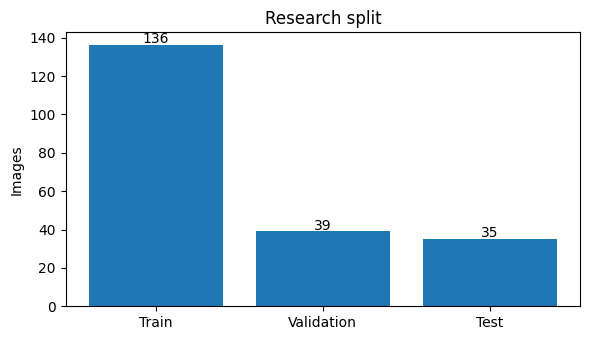

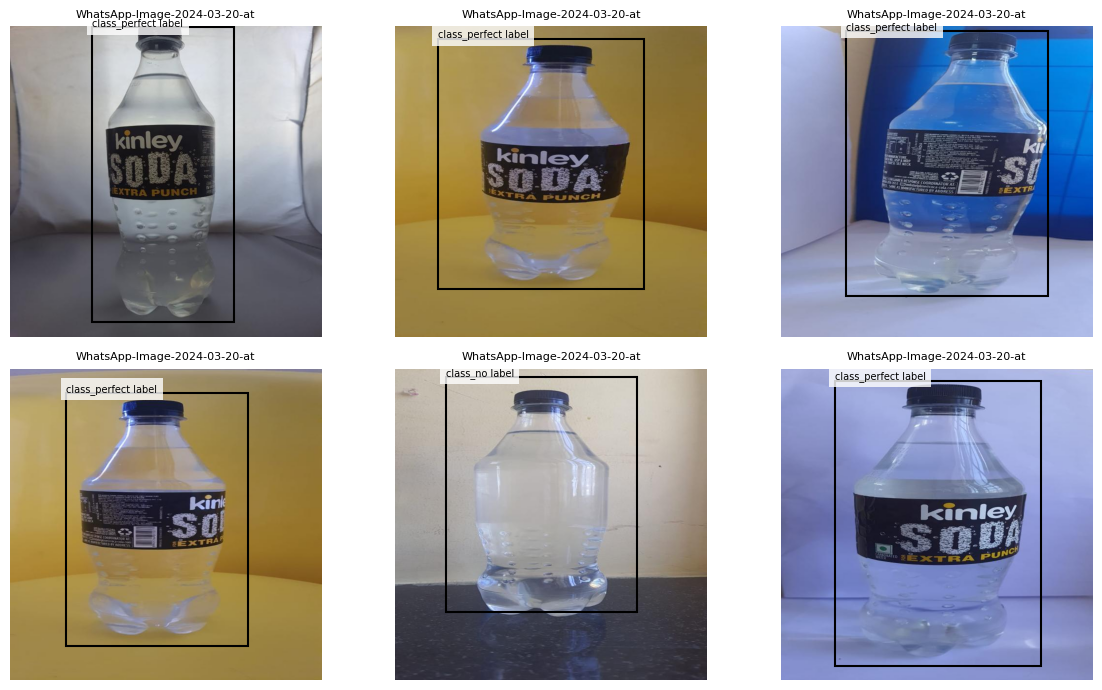

In [8]:
from matplotlib.patches import Rectangle
fig,ax=plt.subplots(figsize=(6,3.5));sizes=[len(final_train),len(val_df),len(test_df)]
ax.bar(['Train','Validation','Test'],sizes)
for i,v in enumerate(sizes):ax.text(i,v+1,str(v),ha='center')
ax.set_title('Research split');ax.set_ylabel('Images');fig.tight_layout();fig.savefig(PLOTS/'split_counts.png',dpi=150);plt.show()
def draw_gt(row,ax):
 with Image.open(row.image) as im:arr=np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
 h,w=arr.shape[:2];ax.imshow(arr)
 for line in Path(row.label).read_text(encoding='utf-8-sig').splitlines():
  if not line.strip():continue
  k,x,y,bw,bh=map(float,line.split());xx=(x-bw/2)*w;yy=(y-bh/2)*h
  ax.add_patch(Rectangle((xx,yy),bw*w,bh*h,fill=False,linewidth=1.5))
  ax.text(xx,max(0,yy-3),CLASS_NAMES[int(k)],fontsize=7,bbox={'facecolor':'white','alpha':.8,'edgecolor':'none'})
 ax.set_title(Path(row.image).name[:28],fontsize=8);ax.axis('off')
sample=final_train.sample(n=min(6,len(final_train)),random_state=SEED)
fig,axes=plt.subplots(2,3,figsize=(12,7))
for ax,(_,row) in zip(axes.flat,sample.iterrows()):draw_gt(row,ax)
for ax in list(axes.flat)[len(sample):]:ax.axis('off')
fig.tight_layout();fig.savefig(PLOTS/'ground_truth_examples.png',dpi=140);plt.show()

## 06 · Stage primary dataset without modifying Kaggle input

In [9]:
STAGED=OUT/'staged_primary'
for split,frame in [('train',final_train),('val',val_df),('test',test_df)]:
 for sub in ('images','labels'):(STAGED/split/sub).mkdir(parents=True,exist_ok=True)
 for _,row in frame.iterrows():
  img=Path(row.image);lbl=Path(row.label);stem=f'{row.sha256[:16]}_{img.stem}'
  shutil.copy2(img,STAGED/split/'images'/(stem+img.suffix.lower()))
  shutil.copy2(lbl,STAGED/split/'labels'/(stem+'.txt'))
prepared={'path':str(STAGED),'train':'train/images','val':'val/images','test':'test/images','names':{i:c for i,c in enumerate(CLASS_NAMES)}}
PREPARED_YAML=CONFIG/'primary_data.yaml';PREPARED_YAML.write_text(yaml.safe_dump(prepared,sort_keys=False))
print(PREPARED_YAML.read_text())

path: /kaggle/working/labelalignment_day24/staged_primary
train: train/images
val: val/images
test: test/images
names:
  0: class_imperfect label
  1: class_no label
  2: class_perfect label



## 07 · Load existing checkpoint OR train (never automatically retrain if available)

In [10]:
# Stable fingerprint ties a checkpoint to this split manifest and primary source.
manifest_fingerprint=hashlib.sha256((REPORT/'research_split_manifest.csv').read_bytes()).hexdigest()
(REPORT/'dataset_split_fingerprint.json').write_text(json.dumps({'sha256':manifest_fingerprint,'primary_source':CFG['primary_source'],'seed':SEED},indent=2))
if MODE not in {'auto','train','reuse','audit'}:raise ValueError('Invalid MODE')
if MODE!='audit':
 if importlib.util.find_spec('ultralytics') is None:subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics>=8.3,<9'])
 from ultralytics import YOLO
 import torch,ultralytics
 DEVICE=0 if torch.cuda.is_available() else 'cpu'
 print('Ultralytics',ultralytics.__version__,'device',DEVICE)
checkpoint=MODELS/'labelalignment_primary_best.pt'
existing=[]
if EXISTING_CHECKPOINT:existing.append(Path(EXISTING_CHECKPOINT))
existing.extend([checkpoint,RUNS/'primary_yolov8n'/'weights'/'best.pt'])
# Search only for explicitly named, previously exported weights, not generic pretrained checkpoints.
if Path('/kaggle/input').exists():existing.extend(sorted(Path('/kaggle/input').rglob('labelalignment_primary_best.pt')))
existing=next((p for p in existing if p.is_file()),None)
if MODE=='audit': MODEL_READY=False;print('Audit-only: no model loaded/trained')
elif MODE=='train' or (MODE=='auto' and existing is None):
 if MODE=='auto':print('No trained checkpoint found; training fresh model.')
 model=YOLO(CFG['pretrained']);start=time.perf_counter()
 train_result=model.train(data=str(PREPARED_YAML),epochs=CFG['epochs'],patience=CFG['patience'],imgsz=CFG['imgsz'],batch=CFG['batch'],workers=CFG['workers'],device=DEVICE,seed=SEED,project=str(RUNS),name='primary_yolov8n',exist_ok=True,save=True,plots=True,verbose=True)
 best=Path(train_result.save_dir)/'weights'/'best.pt'
 if not best.is_file():raise FileNotFoundError(f'Training produced no best.pt: {best}')
 shutil.copy2(best,checkpoint)
 (REPORT/'training_run.json').write_text(json.dumps({'status':'trained','duration_seconds':round(time.perf_counter()-start,2),'checkpoint':str(checkpoint),'ultralytics':ultralytics.__version__,'split_manifest_sha256':manifest_fingerprint},indent=2))
 MODEL_READY=True
else:
 if existing is None:raise FileNotFoundError('MODE=reuse requires EXISTING_CHECKPOINT or mounted saved model. Do not retrain.')
 if existing.resolve()!=checkpoint.resolve():shutil.copy2(existing,checkpoint)
 (REPORT/'training_run.json').write_text(json.dumps({'status':'reused_existing','original_checkpoint':str(existing),'copied_to':str(checkpoint),'split_manifest_sha256':manifest_fingerprint,'note':'Verify original checkpoint used identical train/val/test source split.'},indent=2))
 MODEL_READY=True
if MODEL_READY:
 saved=YOLO(str(checkpoint))
 names={int(k):str(v) for k,v in saved.names.items()} if isinstance(saved.names,dict) else dict(enumerate(saved.names))
 if names!=dict(enumerate(CLASS_NAMES)):raise RuntimeError(f'Checkpoint ontology mismatch: {names}')
 print('READY:',checkpoint,'class mapping:',names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.192 device 0
No trained checkpoint found; training fresh model.
Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/labelalignment_day24/configs/primary_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=Fal

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/65       2.6G      1.489      4.269      1.891         18        640: 100% ━━━━━━━━━━━━ 9/9 10.4it/s 0.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 5.5it/s 0.4s
                   all         39         39      0.435       0.19      0.185     0.0754

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/65       2.6G       1.38      2.513      1.729         18        640: 100% ━━━━━━━━━━━━ 9/9 10.9it/s 0.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 8.7it/s 0.2s
                   all         39         39      0.967      0.214      0.303      0.179

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/65       2.6G      1.227       1.94      1.599         19        640: 100% ━━━━━━━━━━━━ 9/9 9.7it/s 0.9s
                 Class     Images  Instances      Box(P          R    

## 08 · Held-out test evaluation — fixed per-class metric indexing

In [11]:
if MODEL_READY:
 evaluated=saved.val(data=str(PREPARED_YAML),split='test',imgsz=CFG['imgsz'],batch=CFG['batch'],device=DEVICE,project=str(RUNS),name='primary_heldout_test',exist_ok=True,plots=True,verbose=False)
 metric=evaluated.box
 # FIX: in modern Ultralytics metric.ap is a 1D vector already (per-class AP50-95).
 indices=np.asarray(metric.ap_class_index,dtype=int).reshape(-1)
 aps=np.asarray(metric.ap,dtype=float).reshape(-1)
 if len(indices)!=len(aps):raise RuntimeError('AP/class-index length mismatch')
 per_class={CLASS_NAMES[int(i)]:float(v) for i,v in zip(indices,aps)}
 results={'source':CFG['primary_source'],'test_images':len(test_df),'precision':float(metric.mp),'recall':float(metric.mr),'map50':float(metric.map50),'map50_95':float(metric.map),'per_class_ap50_95':per_class,'split_policy':test_policy,'warning':'Detection metrics only; no label-angle/offset or certified pass/fail.'}
 (REPORT/'primary_heldout_metrics.json').write_text(json.dumps(results,indent=2,ensure_ascii=False))
 display(pd.DataFrame([results]).drop(columns=['per_class_ap50_95','warning']))
 display(pd.DataFrame([{'class_name':k,'AP50_95':v} for k,v in per_class.items()]))
else:print('Audit-only: no heldout evaluation')

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 883.9±175.2 MB/s, size: 28.5 KB)
val: Scanning /kaggle/working/labelalignment_day24/staged_primary/test/labels... 35 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 35/35 1.2Kit/s 0.0s
val: New cache created: /kaggle/working/labelalignment_day24/staged_primary/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.0it/s 1.0s
                   all         35         35      0.783      0.926      0.987       0.74
Speed: 5.9ms preprocess, 6.2ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /kaggle/working/labelalignment_day24/runs/primary_heldout_test


,source,test_images,precision,recall,map50,map50_95,split_policy
0,label_v2,35,0.782705,0.925798,0.987,0.739511,group_holdout_from_original_train


,class_name,AP50_95
0,class_imperfect label,0.793010
1,class_no label,0.746450
2,class_perfect label,0.679071


## 09 · Genuine qualitative predictions on held-out images

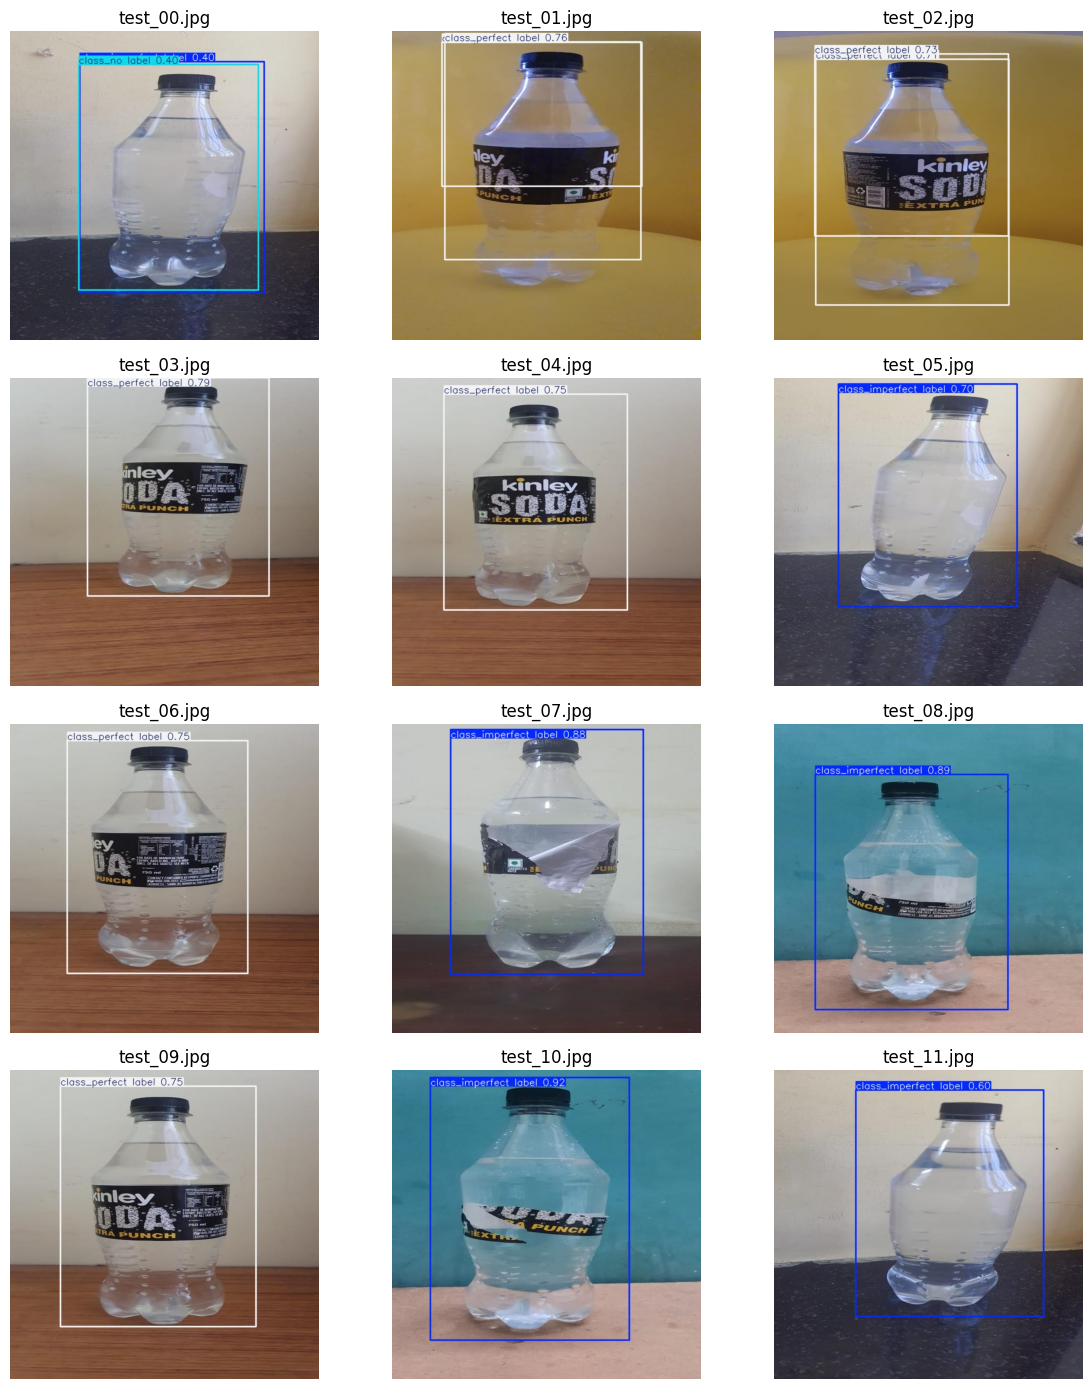

In [12]:
if MODEL_READY:
 import cv2
 chosen=test_df.sample(n=min(CFG['max_examples'],len(test_df)),random_state=SEED)
 for i,(_,row) in enumerate(chosen.iterrows()):
  pred=saved.predict(source=row.image,imgsz=CFG['imgsz'],conf=0.25,verbose=False,device=DEVICE)[0]
  rgb=cv2.cvtColor(pred.plot(),cv2.COLOR_BGR2RGB)
  Image.fromarray(rgb).save(EXAMPLES/f'test_{i:02d}.jpg',quality=90)
 paths=sorted(EXAMPLES.glob('test_*.jpg'))[:len(chosen)]
 cols=3;rows=int(np.ceil(len(paths)/cols));fig,axes=plt.subplots(rows,cols,figsize=(12,3.5*rows),squeeze=False)
 for ax,path in zip(axes.flat,paths):ax.imshow(Image.open(path));ax.set_title(path.name);ax.axis('off')
 for ax in list(axes.flat)[len(paths):]:ax.axis('off')
 fig.tight_layout();fig.savefig(PLOTS/'heldout_predictions.png',dpi=130);plt.show()
else:print('Audit-only: no predictions')

## 09b · Held-out error cases and conservative interpretation

Match boxes by class and IoU ≥ 0.50 with a greedy one-to-one protocol for *qualitative diagnostics only* (not a replacement for Ultralytics mAP). Persist per-image TP/FP/FN and example errors, including errors even when a class is absent. The model is evaluated at one declared confidence threshold; changing this threshold using held-out test would invalidate test independence.


In [13]:
if MODEL_READY:
    from torchvision.ops import box_iou
    import torch
    DIAG_CONF=0.25
    error_rows=[]
    for _,r in test_df.iterrows():
        with Image.open(r.image) as im:
            w,h=im.size
        gt=[]
        for line in Path(r.label).read_text(encoding='utf-8-sig').splitlines():
            if not line.strip():continue
            vals=list(map(float,line.split()));k=int(vals[0]);cx,cy,bw,bh=vals[1:]
            gt.append((k,[(cx-bw/2)*w,(cy-bh/2)*h,(cx+bw/2)*w,(cy+bh/2)*h]))
        pred=saved.predict(source=str(r.image),conf=DIAG_CONF,imgsz=CFG['imgsz'],device=DEVICE,verbose=False)[0]
        pcls=pred.boxes.cls.int().cpu().tolist() if pred.boxes is not None else []
        pboxes=pred.boxes.xyxy.cpu().tolist() if pred.boxes is not None else []
        pconf=pred.boxes.conf.cpu().tolist() if pred.boxes is not None else []
        used=set();tp=fp=0
        for cls,pbox,conf in sorted(zip(pcls,pboxes,pconf),key=lambda t:-t[2]):
            candidates=[(j,float(box_iou(torch.tensor([pbox]),torch.tensor([gbox]))[0,0]))
                        for j,(gcls,gbox) in enumerate(gt) if j not in used and cls==gcls]
            candidates=[(j,iou) for j,iou in candidates if iou>=0.50]
            if candidates:
                j,_=max(candidates,key=lambda pair:pair[1]);used.add(j);tp+=1
            else:fp+=1
        fn=len(gt)-len(used)
        error_rows.append({'image':Path(r.image).name,'gt_objects':len(gt),'predictions':len(pcls),
                           'TP_iou50':tp,'FP_iou50':fp,'FN_iou50':fn,'confidence_threshold':DIAG_CONF})
    diagnostic_df=pd.DataFrame(error_rows)
    diagnostic_df.to_csv(REPORT/'heldout_error_cases.csv',index=False)
    display(diagnostic_df[['TP_iou50','FP_iou50','FN_iou50']].sum().to_frame('total').T)
    display(diagnostic_df.query('FP_iou50 > 0 or FN_iou50 > 0').head(20))
else:
    print('Audit-only mode: no error case analysis.')

,TP_iou50,FP_iou50,FN_iou50
total,32,8,3


,image,gt_objects,predictions,TP_iou50,FP_iou50,FN_iou50,confidence_threshold
13,WhatsApp-Image-2024-03-20-at-18-46-36-2-Copy_j...,1,2,1,1,0,0.25
24,WhatsApp-Image-2024-03-20-at-18-47-52-2-_jpeg....,1,2,1,1,0,0.25
25,WhatsApp-Image-2024-03-20-at-18-47-53-2-_jpeg....,1,2,1,1,0,0.25
26,WhatsApp-Image-2024-03-20-at-18-47-57-Copy-2-_...,1,2,1,1,0,0.25
27,WhatsApp-Image-2024-03-20-at-18-47-58-3-Copy-C...,1,1,0,1,1,0.25
28,WhatsApp-Image-2024-03-20-at-18-47-59-1-Copy_j...,1,2,1,1,0,0.25
29,WhatsApp-Image-2024-03-20-at-18-47-59_jpeg.rf....,1,1,0,1,1,0.25
33,WhatsApp-Image-2024-03-20-at-18-48-15-2-Copy_j...,1,1,0,1,1,0.25


## 10 · Geometry contract — only with verified keypoints/reference

AABB bounding boxes **cannot** identify label orientation or bottle-relative alignment. Measurements require ordered independently verified label corners, bottle axis and reference geometry. No automatic pass/fail.

In [14]:
def analyze_geometry(label_corners,bottle_axis_top,bottle_axis_bottom,reference_center,bottle_width_px,bottle_height_px):
 pts=np.asarray(label_corners,dtype=float);top=np.asarray(bottle_axis_top,dtype=float);bottom=np.asarray(bottle_axis_bottom,dtype=float);ref=np.asarray(reference_center,dtype=float)
 if pts.shape!=(4,2) or not np.isfinite(pts).all():raise ValueError('Need four verified ordered label corners TL TR BR BL')
 if any(np.asarray(p).shape!=(2,) or not np.isfinite(p).all() for p in (top,bottom,ref)):raise ValueError('Reference points must be finite x,y')
 if not all(np.isfinite(v) and v>0 for v in (bottle_width_px,bottle_height_px)):raise ValueError('Reference dimensions must be positive finite')
 axis=bottom-top;upper=pts[1]-pts[0]
 if np.linalg.norm(axis)<1 or np.linalg.norm(upper)<1:raise ValueError('Degenerate geometry')
 horizontal=np.array([axis[1],-axis[0]])
 angle=float(np.degrees(np.arctan2(np.linalg.det(np.stack([horizontal,upper])),np.dot(horizontal,upper))))
 angle=(angle+90)%180-90
 delta=pts.mean(axis=0)-ref
 return {'label_tilt_degrees_relative_to_bottle':round(angle,3),'horizontal_offset_bottle_widths':round(float(np.dot(delta,horizontal/np.linalg.norm(horizontal))/bottle_width_px),5),'vertical_offset_bottle_heights':round(float(np.dot(delta,axis/np.linalg.norm(axis))/bottle_height_px),5),'unit':'relative_bottle_dimensions','quality_decision':'not_assessed','corner_source':'independently_verified_annotation'}
geometry_contract={'required':['label_corners_tl_tr_br_bl','bottle_axis_top','bottle_axis_bottom','reference_center','bottle_width_px','bottle_height_px'],'angle_supported_by_aabb_yolo':False,'offset_supported_without_reference':False,'tolerance_thresholds':'not_specified','pass_fail':'withheld'}
(REPORT/'geometry_contract.json').write_text(json.dumps(geometry_contract,indent=2));print(geometry_contract)

{'required': ['label_corners_tl_tr_br_bl', 'bottle_axis_top', 'bottle_axis_bottom', 'reference_center', 'bottle_width_px', 'bottle_height_px'], 'angle_supported_by_aabb_yolo': False, 'offset_supported_without_reference': False, 'tolerance_thresholds': 'not_specified', 'pass_fail': 'withheld'}


## 11 · Secondary datasets: compare only, no unsafe ontology merging

In [15]:
comparison=[]
for item in inventory:
 name=item['source'];matching=[x for x in yamls if x.get('source')==name and 'error' not in x]
 comparison.append({'source':name,'found':item.get('found',False),'images':item.get('images',0),'yaml_candidates':len(matching),'ontologies':[x['names'] for x in matching],'safe_to_merge':'NO — independent task/label audit required'})
display(pd.DataFrame(comparison))
(REPORT/'source_comparison.json').write_text(json.dumps(comparison,indent=2,ensure_ascii=False))

,source,found,images,yaml_candidates,ontologies,safe_to_merge
0,big_cola,True,377,0,[],NO — independent task/label audit required
1,label_v2,True,210,1,"[[class_imperfect label, class_no label, class...",NO — independent task/label audit required
2,label_other,True,396,0,[],NO — independent task/label audit required
3,water_defects,True,1500,1,"[[bottle_ron88, bottle_other_brand, defect_low...",NO — independent task/label audit required


1079

## 12 · Optional ONNX export (failure does not erase metrics)

In [16]:
export_report={'requested':CFG['onnx_export'],'status':'skipped'}
if MODEL_READY and CFG['onnx_export']:
 try:
  exported=Path(str(YOLO(str(checkpoint)).export(format='onnx',imgsz=CFG['imgsz'],simplify=False,opset=12)))
  if not exported.is_file():raise FileNotFoundError(exported)
  dest=MODELS/'labelalignment_primary_best.onnx'
  if exported.resolve()!=dest.resolve():shutil.copy2(exported,dest)
  export_report={'requested':True,'status':'ok','path':str(dest)}
 except Exception as exc:
  export_report={'requested':True,'status':'failed','error':repr(exc)};print('Optional export failed:',repr(exc))
(REPORT/'onnx_export.json').write_text(json.dumps(export_report,indent=2));print(export_report)

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/labelalignment_day24/models/labelalignment_primary_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)

ONNX: starting export with onnx 1.22.0 opset 12...
ONNX: export success ✅ 0.9s, saved as '/kaggle/working/labelalignment_day24/models/labelalignment_primary_best.onnx' (12.2 MB)

Export complete (1.1s)
Results saved to /kaggle/working/labelalignment_day24/models/labelalignment_primary_best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/labelalignment_day24/models/labelalignment_primary_best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/labelalignment_da

## 13 · Final research summary, integrity checks and artifact ZIP

In [17]:
metrics_path=REPORT/'primary_heldout_metrics.json'
summary={'project':'LabelAlignment QA','day':24,'task':'bottle-label detection baseline + conditional geometry research','primary_source':CFG['primary_source'],'primary_dataset_path':str(SOURCES[CFG['primary_source']]),'classes':CLASS_NAMES,'split_policy':test_policy,'heldout_metrics':json.loads(metrics_path.read_text()) if MODEL_READY and metrics_path.is_file() else None,'checkpoint':str(checkpoint) if MODEL_READY else None,'geometry_measurement_status':'not_computed_requires_verified_corners_and_reference','automatic_pass_fail':'not_provided','limitations':['Axis-aligned boxes cannot directly estimate printed label angle.','Angle/offset require independent reference geometry.','No calibrated manufacturing tolerance for pass/fail.','Small dataset and near duplicates may limit generalization.','Other dataset labels have not been merged.','Verify dataset licensing/attribution before redistribution.']}
(REPORT/'final_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
readme=OUT/'README_ARTIFACTS.md'
readme.write_text("""# LabelAlignment QA — Day 24 research artifacts

Detection baseline with independent held-out evaluation when a checkpoint is available. See `reports/final_summary.json`, `reports/split_policy.json`, `reports/geometry_contract.json`.

No engineering pass/fail certification or automatic physical angle inference. Kaggle input datasets intentionally excluded from archive.
""",encoding='utf-8')
archive=Path('/kaggle/working/LabelAlignmentQA_Day24_Research_Artifacts.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=6) as z:
 for folder in (MODELS,REPORT,PLOTS,EXAMPLES,CONFIG):
  for f in sorted(folder.rglob('*')):
   if f.is_file():z.write(f,f.relative_to(OUT).as_posix())
 z.write(readme,readme.relative_to(OUT).as_posix())
with zipfile.ZipFile(archive) as z:bad=z.testzip();count=len(z.namelist())
if bad is not None:raise RuntimeError(f'ZIP corrupted at {bad}')
print('RELEASE:',archive,'MiB:',round(archive.stat().st_size/1024**2,2),'entries:',count)
print('MODEL_READY:',MODEL_READY,'HELDOUT_METRICS:',summary['heldout_metrics'] is not None)
print('COMPLETE — no fabricated geometry, metrics, or quality decisions.')

RELEASE: /kaggle/working/LabelAlignmentQA_Day24_Research_Artifacts.zip MiB: 20.92 entries: 39
MODEL_READY: True HELDOUT_METRICS: True
COMPLETE — no fabricated geometry, metrics, or quality decisions.


## 14 · Dataset provenance and research gate summary

The generated provenance is an **initial research ledger**, not a license certification. Review each source license and citation requirements from its publisher before distribution. Actual primary training uses only `label_v2`. Final state is *research experiment complete*, **not** deployed product or verified geometric label alignment.


In [18]:
from datetime import datetime, timezone
provenance=[{'source_id':name,'url':SOURCE_URLS[name], 'local_mount':str(root),
             'role':'primary_training' if name==CFG['primary_source'] else 'secondary_inventory_only',
             'dataset_version':'as mounted; verify publisher version',
             'license':'unverified; check publisher page',
             'access_date_utc':datetime.now(timezone.utc).date().isoformat()}
            for name,root in SOURCES.items()]
pd.DataFrame(provenance).to_csv(REPORT/'dataset_provenance.csv',index=False)
assessment={
 'research_training_complete':bool(MODEL_READY),
 'heldout_metrics_file_exists':(REPORT/'primary_heldout_metrics.json').exists(),
 'per_class_distribution_recorded':(REPORT/'split_per_class_counts.csv').exists(),
 'near_duplicate_candidates':len(flags),
 'near_duplicate_human_review':'pending' if flags else 'not_flagged_by_dhash',
 'onnx_export_status':export_report.get('status'),
 'app_end_to_end_verified':False,
 'geometric_angle_offset_validated':False,
 'manufacturing_pass_fail_validated':False,
 'ready_for_production':False,
 'limitations':['Only 35 held-out images','Source class imbalance','Visual near-duplicates require manual assessment','No factory-level external validation']}
(REPORT/'research_gate.json').write_text(json.dumps(assessment,indent=2))
print(json.dumps(assessment,indent=2))
# Recreate the final ZIP to include newly generated audit/provenance reports.
zip_path=Path('/kaggle/working/LabelAlignmentQA_Day24_FINAL_RESEARCH.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as z:
    for directory in (REPORT,PLOTS,MODELS,CONFIG,EXAMPLES):
        for f in sorted(directory.rglob('*')):
            if f.is_file():z.write(f,arcname=f.relative_to(OUT).as_posix())
    for f in [OUT/'README_ARTIFACTS.md']:
        if f.is_file():z.write(f,arcname=f.name)
with zipfile.ZipFile(zip_path) as z:
    corrupt=z.testzip()
    if corrupt:raise RuntimeError(f'ZIP CRC failed: {corrupt}')
    print('FINAL ZIP:',zip_path,'files:',len(z.namelist()),'size MB:',round(zip_path.stat().st_size/1e6,2))

{
  "research_training_complete": true,
  "heldout_metrics_file_exists": true,
  "per_class_distribution_recorded": true,
  "near_duplicate_candidates": 26,
  "near_duplicate_human_review": "pending",
  "onnx_export_status": "ok",
  "app_end_to_end_verified": false,
  "geometric_angle_offset_validated": false,
  "manufacturing_pass_fail_validated": false,
  "ready_for_production": false,
  "limitations": [
    "Only 35 held-out images",
    "Source class imbalance",
    "Visual near-duplicates require manual assessment",
    "No factory-level external validation"
  ]
}
FINAL ZIP: /kaggle/working/LabelAlignmentQA_Day24_FINAL_RESEARCH.zip files: 41 size MB: 21.94
